# CAREMap · 02 Scoring (v2)

Stage 5 of the [project plan](https://claude.ai/artifact/AYBNdGqtaB2AcdvZ3tQKrc). Builds the childcare score, the housing score, the combined score and the priority tiers, using the decisions from Stage 1 and the exploratory analysis:

| Decision | Why |
|---|---|
| Rank metro and nonmetro counties separately (USDA codes 1-3 vs 4-9) | Stage 1 choice; the groups differ a lot on every measure |
| Percentile ranks, not z-scores | Counts and several ratios are heavily skewed |
| Smooth small-county rates (empirical Bayes) before ranking | Tiny counties produce extreme values from small samples |
| Childcare score from kids under 5 per childcare worker. Withheld counties assume 0 employer businesses; 2 businesses is the sensitivity check | Notebook 03: in Michigan the 0-business bound tracks licensed slots far better (rank correlation 0.62 vs 0.38) |
| Housing score = half families (rent burden + home price-to-income), half providers (2-bedroom rent as a share of a childcare worker's pay); rental vacancy dropped | Stage 1: housing for families and providers equally; vacancy looked like noise in notebook 01 |
| Combined score = geometric mean, so a county must be high on both | The project is about where the two problems overlap |
| Screens, not scored: minimum kids under 5; population trend shown as a flag; college counties flagged | Feasibility and data-quality context |

Output: `data/processed/county_scores_v1.csv`, which feeds the v1 map.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
df["group"] = np.where(df["metro"] == True, "Metro", "Nonmetro")
print(f"{len(df):,} counties")

3,144 counties


## Settings

Every judgment call is a named setting here, so it can be changed in one place and shown on the methods page.

In [2]:
MIN_KIDS_UNDER5 = 100        # below this, too few young children to judge or to sustain home-based providers
COLLEGE_FLAG_SHARE = 0.15    # share of residents 3+ enrolled in college or grad school
GROWTH_BANDS = (-2.0, 2.0)   # population change 2020-2025, % : below = declining, above = growing
TOP_SHARE = 0.25             # "top 25%" used for tiers
N_WEIGHT_DRAWS = 1000        # random weightings for the stability check
RNG = np.random.default_rng(42)

## 1. Screens and flags

In [3]:
df["screened_out"] = df["kids_under5"] < MIN_KIDS_UNDER5
df["college_county"] = df["college_share"] >= COLLEGE_FLAG_SHARE
df["pop_trend"] = pd.cut(df["pop_change_pct"], [-np.inf, GROWTH_BANDS[0], GROWTH_BANDS[1], np.inf],
                         labels=["Declining", "Stable", "Growing"])

print(f"Screened out (fewer than {MIN_KIDS_UNDER5} kids under 5): {df['screened_out'].sum()}")
print(df[df["screened_out"]].groupby("group").size().rename("screened out"))
print(f"\nCollege counties (>= {COLLEGE_FLAG_SHARE:.0%} enrolled): {df['college_county'].sum()}")
print(df[df["college_county"]].nlargest(10, "college_share")[["county_name", "USPS", "college_share"]].to_string(index=False))

s = df[~df["screened_out"]].copy()
print(f"\nCounties scored: {len(s):,}")

Screened out (fewer than 100 kids under 5): 109
group
Metro         5
Nonmetro    104
Name: screened out, dtype: int64

College counties (>= 15% enrolled): 71
      county_name USPS  college_share
   Lexington city   VA       0.477459
   Madison County   ID       0.434576
Williamsburg city   VA       0.411671
     Radford city   VA       0.396054
   Whitman County   WA       0.326621
      Clay County   SD       0.307123
Harrisonburg city   VA       0.304270
   Watauga County   NC       0.300730
     Story County   IA       0.299194
 Oktibbeha County   MS       0.297918

Counties scored: 3,035


## 2. Smoothing small-county rates (empirical Bayes)

**What it does:** pulls each county's rate toward its group's average, more strongly when the county's sample is small. A county with 40 renters and 100% burdened moves a lot; a county with 40,000 renters barely moves.

**How:** the group's average rate is the prior. Its strength `m` is estimated from the data (method of moments): how much counties really vary, beyond what small samples alone would cause. Smoothed rate = (count + m × group rate) / (base + m).

- Rent burden: burdened renter households out of renter households.
- Kids per worker: kids under 5 per childcare worker. This also handles counties with zero providers, which would otherwise divide by zero.

In [4]:
def eb_smooth(count, base, kind):
    """Empirical Bayes shrinkage toward the pooled rate.
    kind='proportion' (binomial noise) or 'rate' (Poisson noise per unit of base)."""
    count, base = count.astype(float), base.astype(float)
    ok = base > 0
    r0 = count.sum() / base.sum()
    raw = count[ok] / base[ok]
    noise = r0 * (1 - r0) / base[ok] if kind == "proportion" else r0 / base[ok]
    between = max(raw.var() - noise.mean(), 1e-12)
    m = (r0 * (1 - r0) / between - 1) if kind == "proportion" else r0 / between
    m = max(m, 0.0)
    return (count + m * r0) / (base + m), m


s["burdened"] = s[["rent_pct_30_35", "rent_pct_35_40", "rent_pct_40_50", "rent_pct_50plus"]].sum(axis=1)
s["renters_computed"] = s["renters_total"] - s["rent_pct_not_computed"]

# withheld counties: 0 businesses (low supply) or 2 businesses x median small-county staff (high supply)
published = s[~s["cbp_withheld_0to2"] & (s["cbp_estab"] <= 5)]
staff_per_estab = (published["cbp_emp"] / published["cbp_estab"]).groupby(published["group"]).median()
withheld = s["cbp_withheld_0to2"]
s["workers_low"] = s["cbp_emp"].where(~withheld, 0) + s["nes_estab"]
s["workers_high"] = s["cbp_emp"].where(~withheld, 2 * s["group"].map(staff_per_estab)) + s["nes_estab"]

strengths = []
for g, idx in s.groupby("group").groups.items():
    sub = s.loc[idx]
    s.loc[idx, "rent_burden_eb"], m1 = eb_smooth(sub["burdened"], sub["renters_computed"], "proportion")
    s.loc[idx, "kpw_low_eb"], m2 = eb_smooth(sub["kids_under5"], sub["workers_low"], "rate")
    s.loc[idx, "kpw_high_eb"], m3 = eb_smooth(sub["kids_under5"], sub["workers_high"], "rate")
    strengths.append({"group": g, "rent_burden_m": round(m1, 1), "kids_per_worker_low_m": round(m2, 1),
                      "kids_per_worker_high_m": round(m3, 1)})
pd.DataFrame(strengths)

,group,rent_burden_m,kids_per_worker_low_m,kids_per_worker_high_m
0,Metro,40.5,0.1,0.3
1,Nonmetro,24.3,0.0,0.2


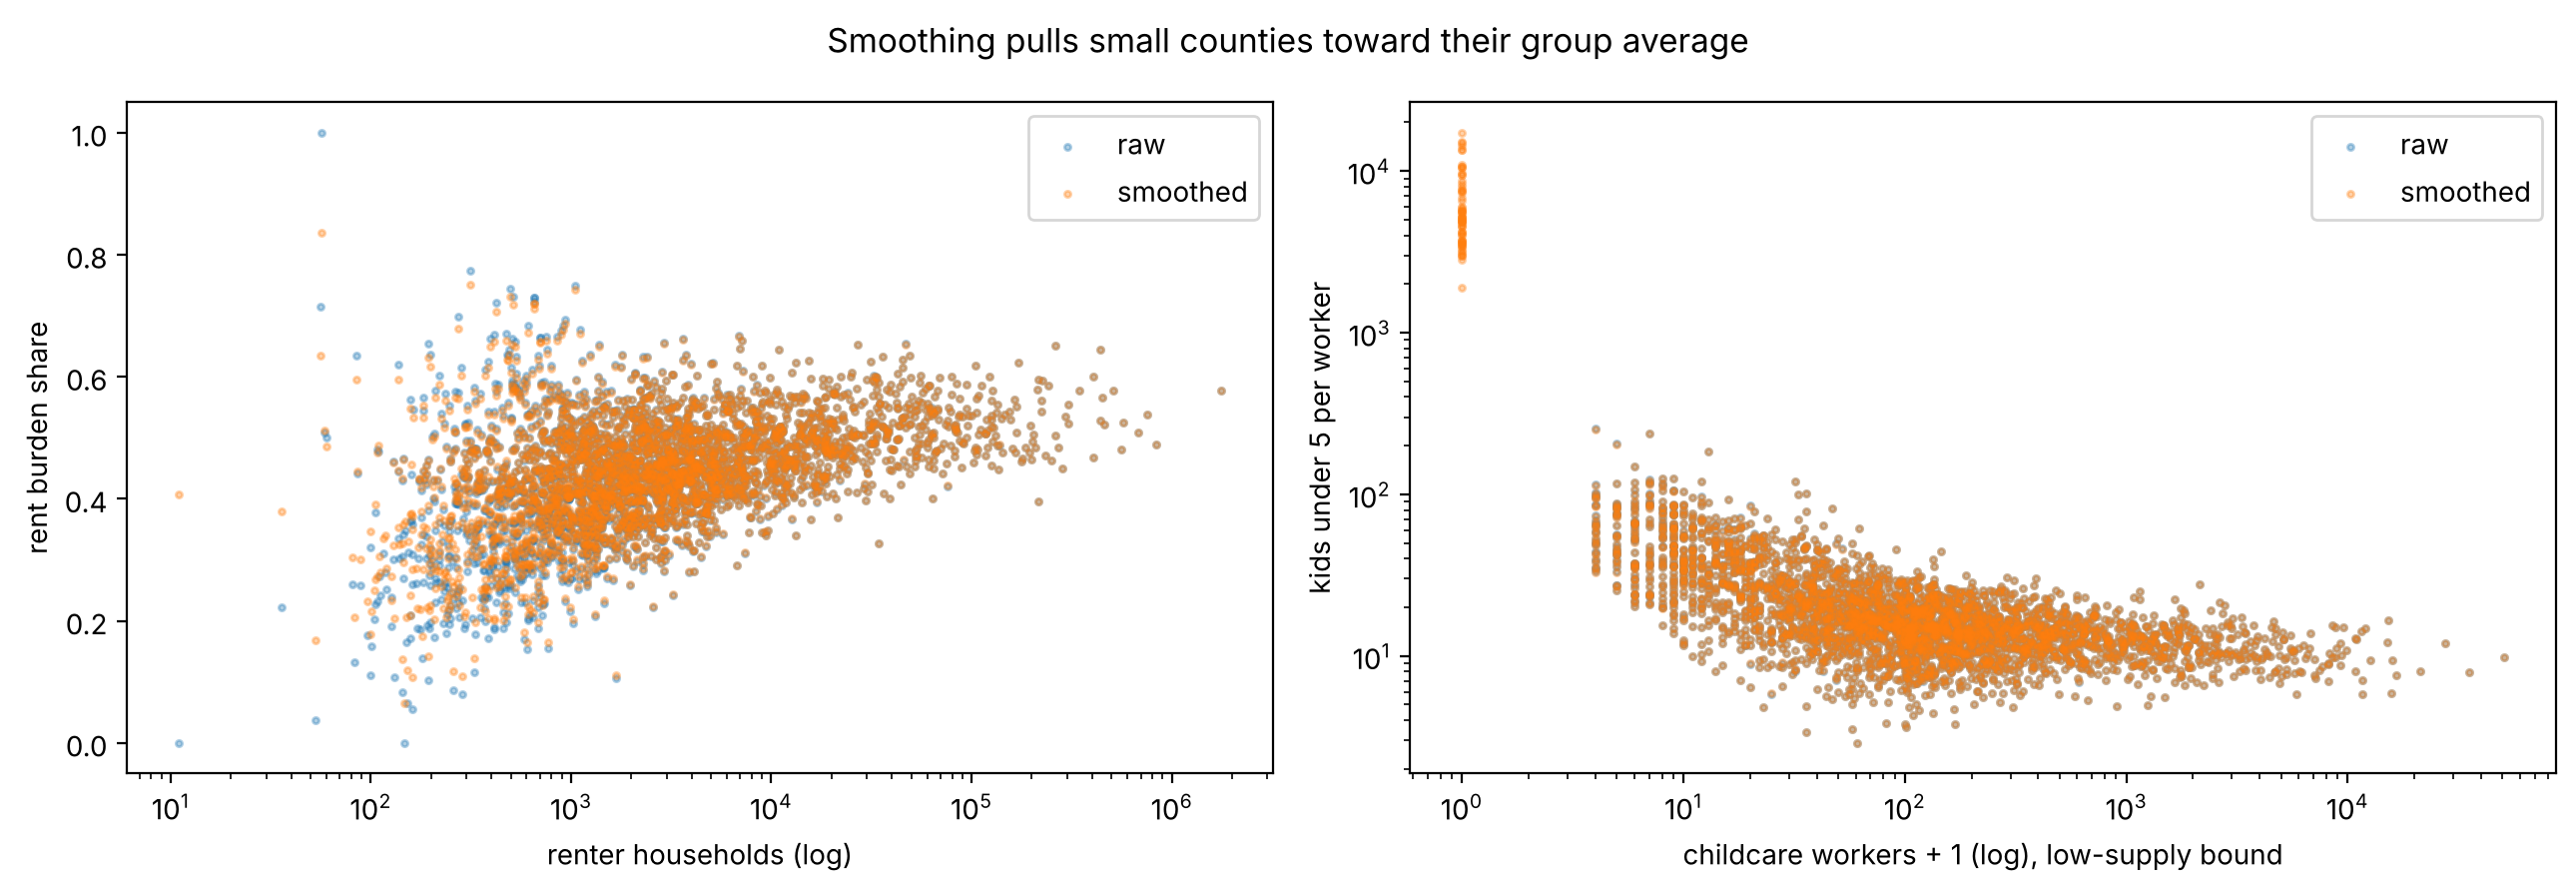

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
raw_rb = s["burdened"] / s["renters_computed"]
axes[0].scatter(s["renters_computed"], raw_rb, s=5, alpha=0.35, label="raw")
axes[0].scatter(s["renters_computed"], s["rent_burden_eb"], s=5, alpha=0.35, label="smoothed")
axes[0].set_xscale("log"); axes[0].set_xlabel("renter households (log)"); axes[0].set_ylabel("rent burden share")
axes[0].legend()
raw_kpw = s["kids_under5"] / s["workers_low"].replace(0, np.nan)
axes[1].scatter(s["workers_low"] + 1, raw_kpw, s=5, alpha=0.35, label="raw")
axes[1].scatter(s["workers_low"] + 1, s["kpw_low_eb"], s=5, alpha=0.35, label="smoothed")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("childcare workers + 1 (log), low-supply bound"); axes[1].set_ylabel("kids under 5 per worker")
axes[1].legend()
fig.suptitle("Smoothing pulls small counties toward their group average")
fig.tight_layout()
fig.savefig(FIG / "02_smoothing.png", dpi=150)
plt.show()

## 2b. Provider housing: can a childcare worker afford local rent?

A year of HUD's 2-bedroom Fair Market Rent divided by the median annual pay of childcare workers in the county's BLS area. Above 0.30 means rent alone would take more than 30% of pay (HUD's cost-burden line). Wages are for employees, so this stands in for what home-based providers earn.

In [6]:
print(f"Counties where a median-paid childcare worker would be rent-burdened (> 30%): "
      f"{(df['provider_rent_share'] > 0.30).mean():.0%}")
print(f"Counties above 50% of pay: {(df['provider_rent_share'] > 0.50).mean():.0%}")
print(f"Counties using a state-median wage (BLS publishes none for their area): {int(df['wage_imputed'].sum())}")
df.groupby("group")["provider_rent_share"].describe().round(3)

Counties where a median-paid childcare worker would be rent-burdened (> 30%): 100%
Counties above 50% of pay: 37%
Counties using a state-median wage (BLS publishes none for their area): 21


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Metro,1186.0,0.561,0.117,0.319,0.474,0.554,0.627,1.342
Nonmetro,1958.0,0.446,0.072,0.314,0.401,0.424,0.479,0.988


## 3. Scores

All percentiles are within the county's own group (metro or nonmetro), 0-100, where 100 = most need.

- **Childcare score**: percentile of smoothed kids per worker, under each bound.
- **Housing score**: half the family side (average of the rent burden and price-to-income percentiles) and half the provider side (percentile of 2-bedroom rent as a share of a childcare worker's median pay), re-ranked to 0-100.
- **Combined score**: geometric mean √(childcare × housing). A county high on only one problem can't score high.

In [7]:
def pct(col):
    return s.groupby("group")[col].rank(pct=True) * 100

s["rent_burden_pctile"] = pct("rent_burden_eb")
s["price_to_income_pctile"] = pct("price_to_income")
s["provider_rent_pctile"] = pct("provider_rent_share")
s["family_housing"] = s[["rent_burden_pctile", "price_to_income_pctile"]].mean(axis=1)
s["housing_raw"] = 0.5 * s["family_housing"] + 0.5 * s["provider_rent_pctile"]
s["housing_score"] = pct("housing_raw")

for b in ("low", "high"):
    s[f"childcare_score_{b}"] = pct(f"kpw_{b}_eb")
    s[f"combined_{b}"] = np.sqrt(s[f"childcare_score_{b}"] * s["housing_score"])

# v2: the 0-business bound ("low") is primary; "high" (2 businesses) is kept as the sensitivity check
s["childcare_score"] = s["childcare_score_low"]
s["combined_score"] = s["combined_low"]
s["rank_in_group"] = s.groupby("group")["combined_score"].rank(ascending=False, method="min").astype(int)
s["withheld_range"] = (s["combined_low"] - s["combined_high"]).abs()
s[["childcare_score", "housing_score", "combined_score", "withheld_range"]].describe().round(1)

,childcare_score,housing_score,combined_score,withheld_range
count,3035.0,3035.0,3035.0,3035.0
mean,50.0,50.0,43.9,6.7
std,28.9,28.9,21.5,7.9
min,0.1,0.1,1.0,0.0
25%,25.0,25.0,27.1,1.8
50%,50.0,50.1,43.8,4.0
75%,75.0,75.0,60.7,9.3
max,100.0,100.0,97.3,76.7


## 4. Tiers

Per bound: **High** = childcare and housing scores both in the group's top 25%; **Medium** = combined score in the top 25% otherwise; **Low** = the rest.

Scores, ranks and tiers use the 0-business assumption for withheld counties (v2, based on the Michigan validation). A High county that would not be High under the 2-business assumption is flagged `high_if_zero` and reported as **High, unconfirmed**: a likely candidate whose withheld data keeps it from being confirmed. Confirmed High = High under both assumptions.

In [8]:
TIER_ORDER = {"Low": 0, "Medium": 1, "High": 2}

def tiers(b):
    cut = 100 * (1 - TOP_SHARE)
    combined_cut = s.groupby("group")[f"combined_{b}"].transform(lambda x: x.quantile(1 - TOP_SHARE))
    both_high = (s[f"childcare_score_{b}"] >= cut) & (s["housing_score"] >= cut)
    return np.select([both_high, s[f"combined_{b}"] >= combined_cut], ["High", "Medium"], "Low")

s["tier_low"], s["tier_high"] = tiers("low"), tiers("high")
# Tier and rank both use the 0-business estimate (the best estimate per notebook 03).
# A High that holds only under that assumption is flagged as unconfirmed: inside withheld counties the
# proxy barely tracked licensed slots in Michigan, so these need local data to confirm.
s["tier"] = s["tier_low"]
s["high_if_zero"] = (s["tier_low"] == "High") & (s["tier_high"] != "High")
s["tier_uncertain"] = s["tier_low"] != s["tier_high"]

pd.crosstab(s["group"], s["tier"], margins=True)

tier,High,Low,Medium,All
group,,,,
Metro,30,885,266,1181
Nonmetro,76,1390,388,1854
All,106,2275,654,3035


In [9]:
print(f"High, confirmed (both assumptions): {int(((s['tier']=='High') & ~s['high_if_zero']).sum())}; High, unconfirmed (0-business only): {int(s['high_if_zero'].sum())}")
print(s[s["high_if_zero"]].groupby("group").size().to_string())
print("Tier depends on the withheld-business assumption:")
print(s.groupby("group")["tier_uncertain"].agg(["sum", "mean"]).round(3))

High, confirmed (both assumptions): 63; High, unconfirmed (0-business only): 43
group
Metro        5
Nonmetro    38
Tier depends on the withheld-business assumption:
          sum   mean
group               
Metro      63  0.053
Nonmetro  324  0.175


## 5. Stability across weightings (research question 3)

The combined score above weights childcare and housing equally, families and providers equally, and rent burden and price-to-income equally. Here 1,000 random weightings are drawn (childcare weight 30-70%; family vs. provider weight 30-70%; rent burden vs. price-to-income anywhere from 0-100%), using the 0-business assumption. `stable_share` is how often a county lands in its group's top 25%. A county at 90%+ is a top candidate under almost any reasonable weighting.

In [10]:
hits = pd.Series(0.0, index=s.index)
for _ in range(N_WEIGHT_DRAWS):
    w_child = RNG.uniform(0.3, 0.7)
    w_rent = RNG.uniform(0, 1)
    w_family = RNG.uniform(0.3, 0.7)
    b = "low"
    housing = s.groupby("group").apply(
        lambda g: (w_family * (w_rent * g["rent_burden_pctile"] + (1 - w_rent) * g["price_to_income_pctile"])
                   + (1 - w_family) * g["provider_rent_pctile"]).rank(pct=True) * 100,
        include_groups=False,
    ).reset_index(level=0, drop=True)
    combined = s[f"childcare_score_{b}"] ** w_child * housing ** (1 - w_child)
    cut = combined.groupby(s["group"]).transform(lambda x: x.quantile(1 - TOP_SHARE))
    hits += (combined >= cut)
s["stable_share"] = hits / N_WEIGHT_DRAWS

print("Counties in the top 25% under 90%+ of weightings:")
print(s[s["stable_share"] >= 0.9].groupby("group").size())

Counties in the top 25% under 90%+ of weightings:
group
Metro       178
Nonmetro    237
dtype: int64


## 6. Top counties by group

In [11]:
cols = ["rank_in_group", "county_name", "USPS", "kids_under5", "childcare_score", "housing_score",
        "combined_score", "tier", "tier_uncertain", "stable_share", "pop_trend", "college_county"]
for g in ("Metro", "Nonmetro"):
    print(f"\n{g}: top 15")
    display(s[s["group"] == g].sort_values("rank_in_group")[cols].head(15).round(1))


Metro: top 15


,rank_in_group,county_name,USPS,kids_under5,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share,pop_trend,college_county
2843,1,Clarke County,VA,628,93.0,98.5,95.7,High,False,1.0,Growing,False
552,2,Maui County,HI,8821,89.8,99.2,94.4,High,False,1.0,Declining,False
500,3,Pickens County,GA,1598,94.4,93.2,93.8,High,False,1.0,Growing,False
255,4,Clear Creek County,CO,254,95.3,88.4,91.7,High,True,1.0,Declining,False
213,5,Monterey County,CA,28601,85.4,98.1,91.5,High,False,1.0,Stable,False
2805,6,Washington County,UT,11732,89.3,93.7,91.5,High,False,1.0,Growing,False
1603,7,Broadwater County,MT,405,93.8,88.8,91.3,High,True,1.0,Growing,False
2324,8,Beaufort County,SC,9020,83.1,96.4,89.5,High,False,1.0,Growing,False
3,9,Bibb County,AL,1092,95.7,82.2,88.7,High,False,1.0,Stable,False
549,10,Honolulu County,HI,56781,78.2,99.5,88.2,High,False,1.0,Declining,False



Nonmetro: top 15


,rank_in_group,county_name,USPS,kids_under5,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share,pop_trend,college_county
2646,1,Jeff Davis County,TX,133,97.5,97.1,97.3,High,True,1.0,Declining,False
2740,2,Sterling County,TX,118,97.1,93.0,95.0,High,True,1.0,Declining,False
248,3,Archuleta County,CO,530,92.3,96.9,94.6,High,False,1.0,Growing,False
2674,4,Llano County,TX,911,86.5,98.8,92.4,High,False,1.0,Growing,False
2880,5,Middlesex County,VA,380,87.3,97.4,92.2,High,True,1.0,Growing,False
2714,6,Rains County,TX,549,89.8,94.7,92.2,High,False,1.0,Growing,False
2643,7,Jack County,TX,499,89.9,93.2,91.5,High,True,1.0,Growing,False
2719,8,Reeves County,TX,876,96.4,86.7,91.4,High,False,1.0,Declining,False
527,9,Towns County,GA,413,90.6,92.2,91.4,High,True,1.0,Growing,False
2627,10,Hartley County,TX,380,99.6,83.5,91.2,High,False,1.0,Declining,False


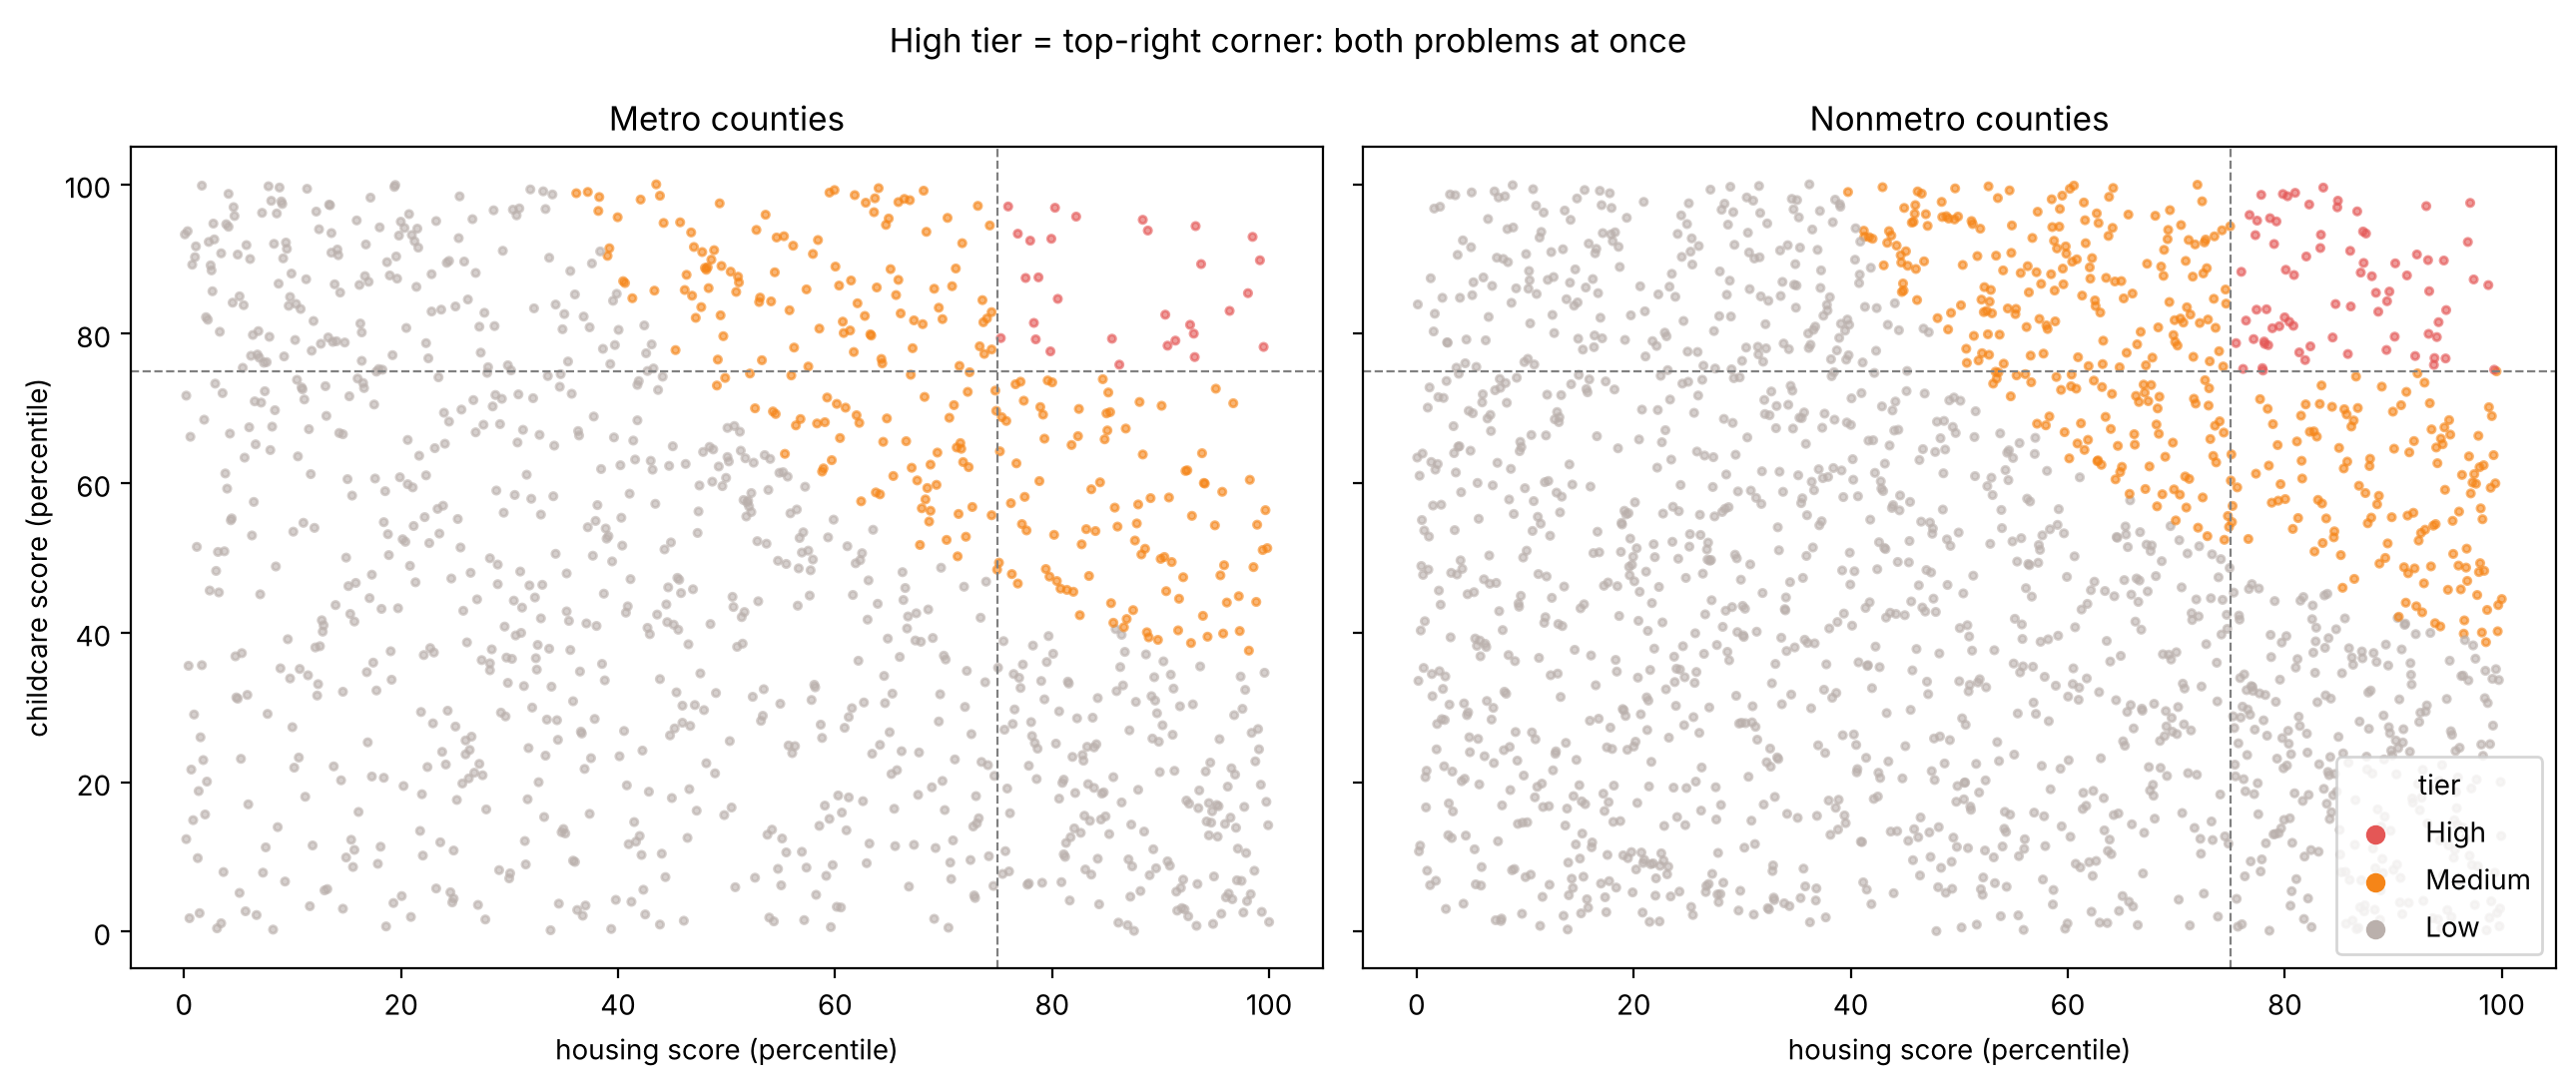

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
colors = {"High": "#E45756", "Medium": "#F58518", "Low": "#BAB0AC"}
for ax, g in zip(axes, ("Metro", "Nonmetro")):
    sub = s[s["group"] == g]
    ax.scatter(sub["housing_score"], sub["childcare_score"], s=7, alpha=0.6, c=sub["tier"].map(colors))
    ax.axvline(75, color="gray", lw=0.8, ls="--"); ax.axhline(75, color="gray", lw=0.8, ls="--")
    ax.set_title(f"{g} counties"); ax.set_xlabel("housing score (percentile)")
axes[0].set_ylabel("childcare score (percentile)")
for t, c in colors.items():
    axes[1].scatter([], [], c=c, label=t)
axes[1].legend(title="tier", loc="lower right")
fig.suptitle("High tier = top-right corner: both problems at once")
fig.tight_layout()
fig.savefig(FIG / "02_tiers.png", dpi=150)
plt.show()

## 7. Sanity check on places we know

In [13]:
check = ["26163", "26049", "26125", "26099", "26161"]  # Wayne, Genesee, Oakland, Macomb, Washtenaw (MI)
s[s["GEOID"].isin(check)][["county_name", "group", "rank_in_group", "childcare_score", "housing_score",
                           "combined_score", "tier", "stable_share", "college_county"]].round(1)

,county_name,group,rank_in_group,childcare_score,housing_score,combined_score,tier,stable_share,college_county
1257,Genesee County,Metro,956,22.4,24.1,23.2,Low,0.0,False
1282,Macomb County,Metro,210,74.4,56.0,64.5,Medium,0.9,False
1295,Oakland County,Metro,551,38.5,51.5,44.5,Low,0.0,False
1313,Washtenaw County,Metro,853,9.4,90.6,29.2,Low,0.0,True
1314,Wayne County,Metro,578,32.7,58.2,43.6,Low,0.0,False


In [14]:
mi = s[s["USPS"] == "MI"].sort_values("combined_score", ascending=False)
print(f"Michigan: {len(mi)} counties scored; tiers:")
print(mi["tier"].value_counts())
mi[["county_name", "group", "rank_in_group", "childcare_score", "housing_score", "combined_score",
    "tier", "tier_uncertain", "stable_share"]].head(10).round(1)

Michigan: 82 counties scored; tiers:
tier
Low       56
Medium    26
Name: count, dtype: int64


,county_name,group,rank_in_group,childcare_score,housing_score,combined_score,tier,tier_uncertain,stable_share
1275,Lake County,Nonmetro,56,94.4,75.0,84.1,Medium,False,1.0
1268,Iron County,Nonmetro,181,87.5,63.5,74.6,Medium,False,0.9
1252,Crawford County,Nonmetro,187,84.7,65.2,74.3,Medium,False,1.0
1234,Alger County,Nonmetro,203,99.2,54.6,73.6,Medium,True,0.9
1280,Luce County,Nonmetro,226,94.5,54.9,72.0,Medium,True,0.7
1237,Antrim County,Nonmetro,242,77.5,65.4,71.2,Medium,False,0.8
1292,Montmorency County,Nonmetro,245,85.8,58.8,71.0,Medium,True,0.9
1235,Allegan County,Nonmetro,251,55.4,89.9,70.6,Medium,False,1.0
1249,Chippewa County,Nonmetro,264,75.5,64.8,69.9,Medium,False,1.0
1250,Clare County,Nonmetro,277,75.9,63.2,69.3,Medium,False,0.9


## 8. Save scores for the map

In [15]:
out_cols = ["GEOID", "USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
            "childcare_score", "childcare_score_low", "childcare_score_high", "housing_score",
            "rent_burden_pctile", "price_to_income_pctile", "provider_rent_pctile", "combined_score", "combined_low", "combined_high",
            "rank_in_group", "tier", "tier_uncertain", "high_if_zero", "stable_share",
            "rent_burden_eb", "price_to_income", "provider_rent_share", "fmr_2br", "childcare_wage", "wage_imputed",
            "rental_vacancy_rate", "workers_low", "workers_high", "kpw_low_eb", "kpw_high_eb",
            "cbp_withheld_0to2", "pop_change_pct", "pop_trend", "college_share", "college_county", "median_hh_income"]
scores = df[["GEOID", "USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
             "rental_vacancy_rate", "price_to_income", "cbp_withheld_0to2", "pop_change_pct", "pop_trend",
             "college_share", "college_county", "median_hh_income"]].merge(
    s[[c for c in out_cols if c not in ("USPS", "county_name", "group", "rucc_2023", "kids_under5", "screened_out",
                                         "rental_vacancy_rate", "price_to_income", "cbp_withheld_0to2",
                                         "pop_change_pct", "pop_trend", "college_share", "college_county",
                                         "median_hh_income")]],
    on="GEOID", how="left")[out_cols]
scores.loc[scores["screened_out"], "tier"] = "Not scored"
scores.to_csv(ROOT / "data/processed/county_scores_v1.csv", index=False)
print(f"Saved {len(scores):,} counties to data/processed/county_scores_v1.csv")
scores["tier"].value_counts()

Saved 3,144 counties to data/processed/county_scores_v1.csv


tier
Low           2275
Medium         654
Not scored     109
High           106
Name: count, dtype: int64

## Notes

What to check before the map: do the top counties make sense to you, and does anything in the Michigan list look wrong for reasons the data can't see?